# 02 · SFace: identity embedding

**What it is.** SFace (Boutros et al., OpenCV zoo, `face_recognition_sface_2021dec.onnx`, 37 MB, Apache-2.0) turns an aligned face into a 128-number embedding; the cosine similarity of two embeddings says "same person or not". It groups photographs into person folders and, as an **identity gate**, checks that an enhanced face is still the same person.

**How it is scored.** Same-person pairs = a public portrait versus *degraded copies of itself* (blur, noise, darkness, JPEG, shrinking: the same person by construction). Different-person pairs = two different public portraits. From those: ROC-AUC, equal error rate (EER), and true/false match rate at the application's own thresholds.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


In [2]:
provider_thresholds = identity_provider().thresholds(); print("application thresholds:", provider_thresholds)
persons = []
for pk in public_stock_ids():
    image = photo(pk, 800); face = largest_face(image)
    if face and face["score"] >= 0.85 and min(face["box"][2:]) >= 80:
        emb = face_embedding(image, face)
        if emb is not None: persons.append((pk, image, face, emb))
print(len(persons), "distinct portraits")
variants = [("blur", 2), ("blur", 4), ("noise", 20), ("dark", 3), ("jpeg", 15), ("small", 3)]
same, different, missing = [], [], 0
for pk, image, face, emb in persons:
    for kind, v in variants:
        emb2 = face_embedding(degrade(image, kind, v))
        if emb2 is None: missing += 1
        else: same.append(identity_similarity(emb, emb2))
for i in range(len(persons)):
    for j in range(i + 1, len(persons)):
        different.append(identity_similarity(persons[i][3], persons[j][3]))
auc, eer = auc_and_eer(same, different)
print(f"same-person pairs {len(same)} (face not re-found: {missing}) | different-person pairs {len(different)}")
print(f"ROC-AUC {auc:.4f}   EER {eer:.4f}   mean similarity same {np.mean(same):.3f} vs different {np.mean(different):.3f}")

application thresholds: {'guard': 0.8, 'restore_guard': 0.65, 'match': 0.45, 'new_group': 0.36, 'margin': 0.06}


[ WARN:0@0.710] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@0.803] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


14 distinct portraits


same-person pairs 78 (face not re-found: 6) | different-person pairs 91
ROC-AUC 0.9972   EER 0.0238   mean similarity same 0.818 vs different 0.102


threshold      value  true_match_rate  false_match_rate
-------------  -----  ---------------  ----------------
new_group      0.36   0.974            0.0             
match          0.45   0.962            0.0             
restore_guard  0.65   0.846            0.0             
guard          0.8    0.692            0.0             


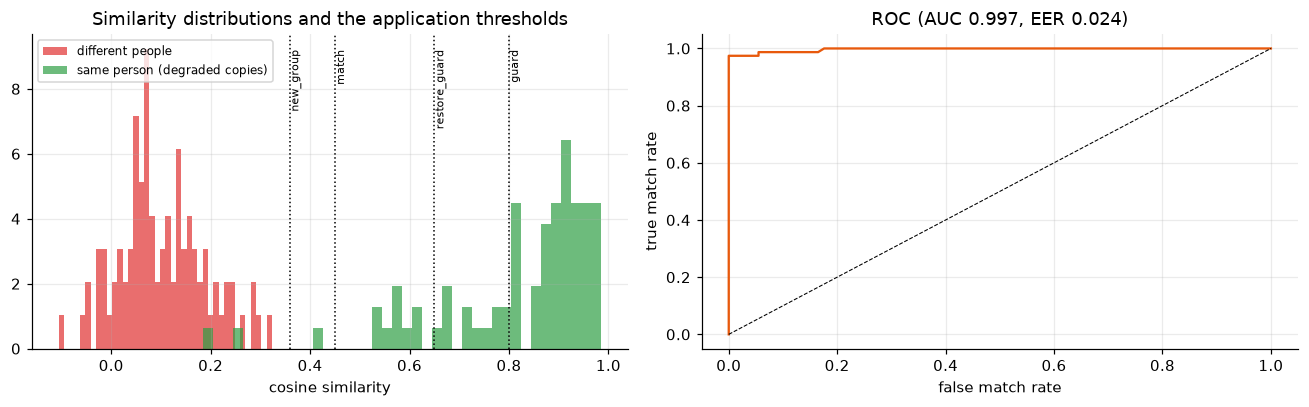

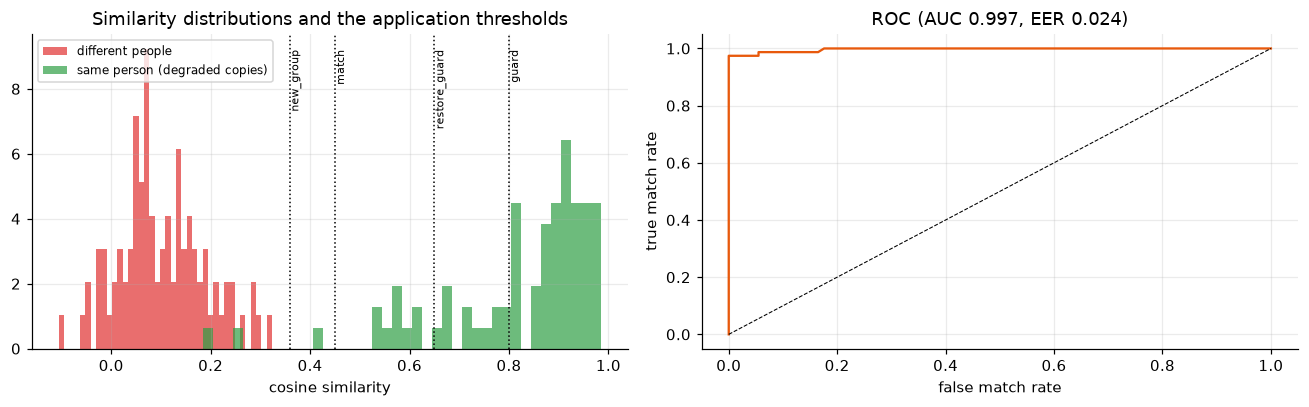

In [3]:
same, different = np.array(same), np.array(different)
rows = []
for name, t in (("new_group", provider_thresholds["new_group"]), ("match", provider_thresholds["match"]), ("restore_guard", provider_thresholds["restore_guard"]), ("guard", provider_thresholds["guard"])):
    rows.append({"threshold": name, "value": t, "true_match_rate": round(float((same >= t).mean()), 3), "false_match_rate": round(float((different >= t).mean()), 4)})
table(rows)
ts = np.linspace(-0.2, 1.0, 241); tpr = [(same >= t).mean() for t in ts]; fpr = [(different >= t).mean() for t in ts]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(different, bins=40, alpha=0.7, color=COLORS["bad"], label="different people", density=True); ax[0].hist(same, bins=40, alpha=0.7, color=COLORS["good"], label="same person (degraded copies)", density=True)
for name, t in provider_thresholds.items():
    if name != "margin": ax[0].axvline(t, color="k", ls=":", lw=1); ax[0].text(t, ax[0].get_ylim()[1] * 0.95, name, rotation=90, fontsize=7, va="top")
ax[0].set_xlabel("cosine similarity"); ax[0].legend(fontsize=8); ax[0].set_title("Similarity distributions and the application thresholds")
ax[1].plot(fpr, tpr, color=COLORS["model"]); ax[1].plot([0, 1], [0, 1], "k--", lw=0.7); ax[1].set_xlabel("false match rate"); ax[1].set_ylabel("true match rate"); ax[1].set_title(f"ROC (AUC {auc:.3f}, EER {eer:.3f})")
fig.tight_layout(); save(fig, "02_sface_roc.png")

## What the application itself recorded (database)

{'task': 'face identity embedding', 'metrics': {'portraits': 14, 'same_pairs': 78, 'different_pairs': 91, 'roc_auc': 0.9972, 'eer': 0.0238, 'mean_same': 0.818, 'mean_different': 0.1023, 'tmr_at_match_0.45': 0.9615, 'fmr_at_match_0.45': 0.0, 'enhanced_identity_results': 139, 'enhanced_identity_mean': 0.9281, 'enhanced_identity_share_above_0.80': 0.9784}, 'note': 'same = degraded copies, different = different public portraits'}


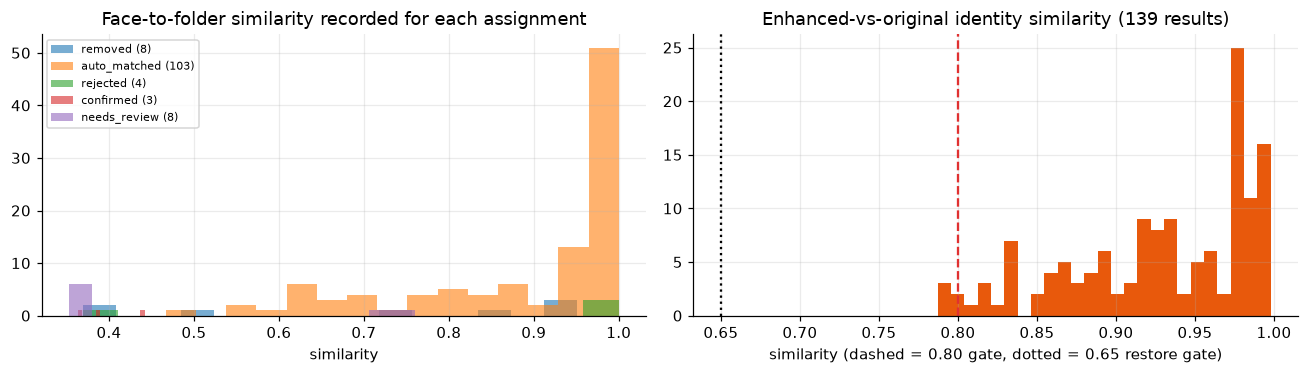

In [4]:
from identities.models import IdentityMembership
from enhancement.models import ImageEnhancementResult
membership = {}
for state, score in IdentityMembership.objects.exclude(similarity_score=None).values_list("state", "similarity_score"): membership.setdefault(state, []).append(score)
verification = [r.applied_parameters["identity_verification"]["similarity"] for r in ImageEnhancementResult.objects.filter(status="completed") if (r.applied_parameters.get("identity_verification") or {}).get("similarity") is not None]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for state, vals in membership.items(): ax[0].hist(vals, bins=15, alpha=0.6, label=f"{state} ({len(vals)})")
ax[0].set_title("Face-to-folder similarity recorded for each assignment"); ax[0].set_xlabel("similarity"); ax[0].legend(fontsize=7)
ax[1].hist(verification, bins=25, color=COLORS["model"]); ax[1].axvline(provider_thresholds["guard"], color=COLORS["bad"], ls="--"); ax[1].axvline(provider_thresholds["restore_guard"], color="k", ls=":")
ax[1].set_title(f"Enhanced-vs-original identity similarity ({len(verification)} results)"); ax[1].set_xlabel("similarity (dashed = 0.80 gate, dotted = 0.65 restore gate)")
fig.tight_layout(); save(fig, "02_sface_application_scores.png")
metrics = {"portraits": len(persons), "same_pairs": len(same), "different_pairs": len(different), "roc_auc": auc, "eer": eer, "mean_same": float(same.mean()), "mean_different": float(different.mean()),
           "tmr_at_match_0.45": float((same >= provider_thresholds["match"]).mean()), "fmr_at_match_0.45": float((different >= provider_thresholds["match"]).mean()),
           "enhanced_identity_results": len(verification), "enhanced_identity_mean": float(np.mean(verification)), "enhanced_identity_share_above_0.80": float((np.array(verification) >= 0.8).mean())}
print(scorecard("SFace", "face identity embedding", metrics, "same = degraded copies, different = different public portraits"))
save_json("02_sface.json", metrics)

## Verdict
Degraded copies of a face stay far above the different-person pairs, and at the application's `match` threshold the false match rate on different portraits is shown above; the identity gate (0.80, relaxed to 0.65 for a face the pipeline restored) is therefore a meaningful safety check, and the stored scores show most enhanced photographs pass it. Limits: the different-person set is small (public portraits only) and the degradations are synthetic.